# 🎨 The Policy Briefing in 40 Minutes
### Unit 1 Activity — Colour Theory in Data Visualization (UE24CS342AA9)

---

**11:00 AM.** You're a junior analyst at **GlobalIndex Insights**. In 40 minutes you're
presenting well-being trends to a policy think-tank. Your Creative Director, Meera,
left these notes:

> *"Every chart in this draft misuses color somewhere -- wrong scale type, no
> accessible palette, a rainbow colormap, you name it. Fix each one using the right
> color-mapping principle. I've marked what's broken with a `# TODO`."*

Same dataset the team has been using: the World Happiness Report 2015.

## ⏱️ Setup — run this first

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import TwoSlopeNorm
import time

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

df = pd.read_csv("D:\\VDUI_HANDSON\\unit1\\ppt6\\ppt6_2015.csv")
mission_start = time.time()
print(f"Loaded {len(df)} rows. 40 minutes on the clock. Go.")
df.head()

Loaded 158 rows. 40 minutes on the clock. Go.


,Country,Region,Happiness Rank,Happiness Score,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204
3,Norway,Western Europe,4,7.522,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531
4,Canada,North America,5,7.427,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176


In [5]:
# Run any time to check your remaining budget
elapsed_min = (time.time() - mission_start) / 60
remaining = max(0, 40 - elapsed_min)
print(f"Elapsed: {elapsed_min:0.1f} min   |   Remaining: {remaining:0.1f} min")

Elapsed: 0.5 min   |   Remaining: 39.5 min


---
## Task 1 — Pick the Right Aesthetic *(~4 min)*

Meera's note: *"We need to compare Economy (GDP per Capita) across the top 10
countries. Right now it's plotted with only position -- add color as a SECOND aesthetic
encoding the same variable, so the redundancy makes the comparison unmistakable."*

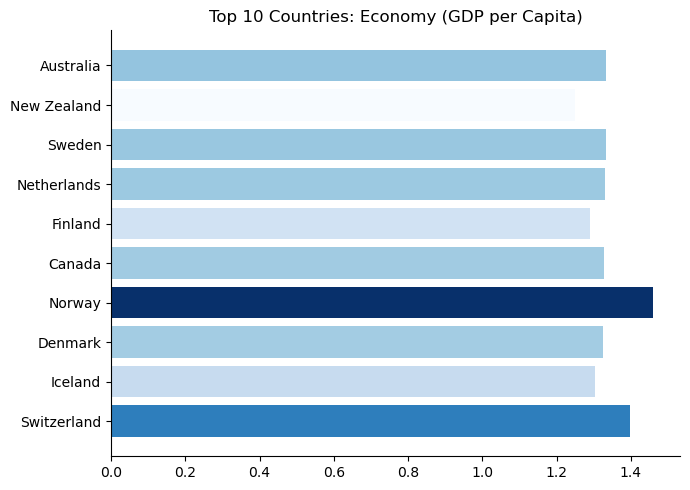

In [6]:
top10 = df.nsmallest(10, "Happiness Rank")

fig, ax = plt.subplots(figsize=(7, 5))

# Map Economy (GDP per Capita) onto a sequential colormap so color reinforces position
values = top10["Economy (GDP per Capita)"]
bar_colors = plt.cm.Blues(plt.Normalize()(values))

ax.barh(top10["Country"], values, color=bar_colors)
ax.set_title("Top 10 Countries: Economy (GDP per Capita)")
plt.tight_layout()
plt.show()

---
## Task 2 — Build the Region x Factor Heatmap *(~5 min)*

Meera's note: *"I want the exact 'average value in a colored matrix' chart from the
lecture -- rows are regions, columns are well-being factors, cell color is the average
score. Use a sequential colormap since there's no natural zero-midpoint here."*

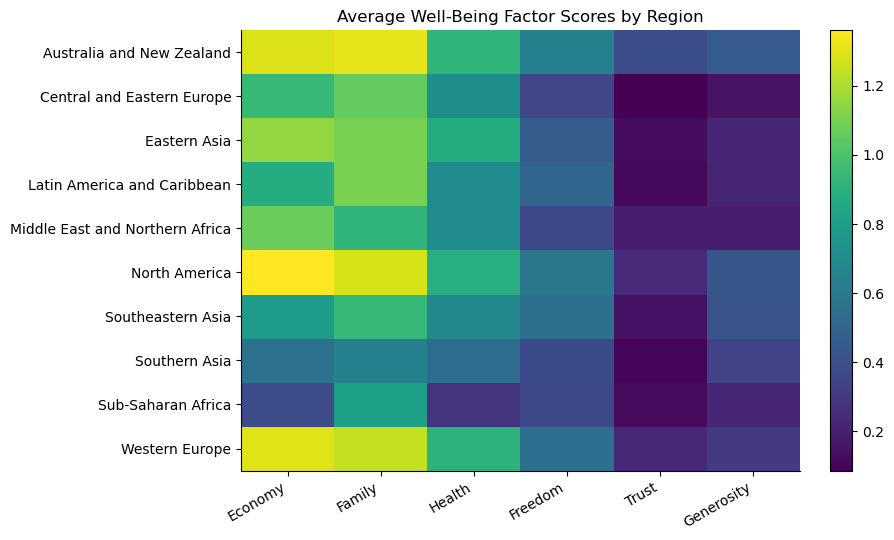

In [7]:
factor_cols = ["Economy (GDP per Capita)", "Family", "Health (Life Expectancy)",
               "Freedom", "Trust (Government Corruption)", "Generosity"]

# Region x factor matrix: mean of each factor, grouped by Region
region_matrix = df.groupby("Region")[factor_cols].mean()

fig, ax = plt.subplots(figsize=(9, 5.5))

# Sequential colormap: values only go from low to high with no meaningful zero-midpoint
im = ax.imshow(region_matrix.values, cmap="viridis", aspect="auto")

ax.set_xticks(range(len(factor_cols)))
ax.set_xticklabels([c.split(" (")[0] for c in factor_cols], rotation=30, ha="right")
ax.set_yticks(range(len(region_matrix)))
ax.set_yticklabels(region_matrix.index)
plt.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Average Well-Being Factor Scores by Region")
plt.tight_layout()
plt.show()

---
## Task 3 — Fix the Qualitative Scale *(~5 min)*

Meera's note: *"This regional comparison chart currently colors every country the same
color -- there's no way to see the regional pattern. Give each region its own
consistent, equally-weighted color."*

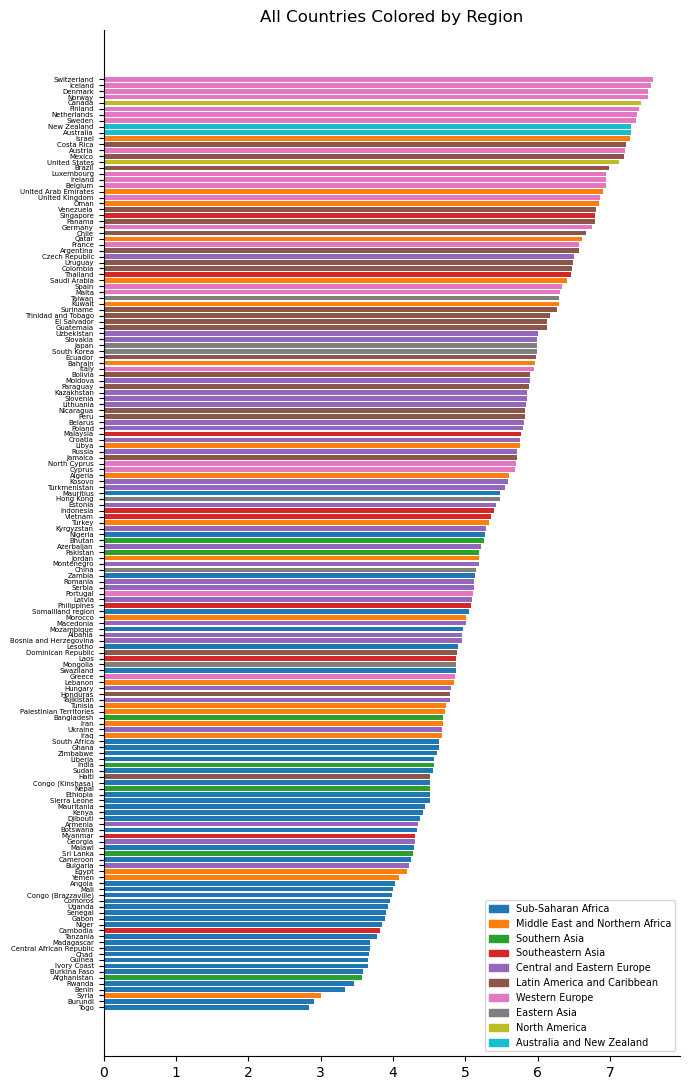

In [8]:
ordered = df.sort_values("Happiness Score", ascending=True)
regions = ordered["Region"].unique()

# Distinct, equally-weighted qualitative color per region (tab10 is built for this: no
# region's color implies "more" or "less" than another's -- they're categorical, not ordinal)
cmap = plt.cm.tab10
color_map = {region: cmap(i % 10) for i, region in enumerate(regions)}

bar_colors = ordered["Region"].map(color_map)

fig, ax = plt.subplots(figsize=(7, 11))
ax.barh(ordered["Country"], ordered["Happiness Score"], color=bar_colors)
ax.tick_params(axis="y", labelsize=5)
ax.set_title("All Countries Colored by Region")

handles = [patches.Patch(color=color_map[r], label=r) for r in regions]
ax.legend(handles=handles, loc="lower right", fontsize=7)
plt.tight_layout()
plt.show()

---
## Task 4 — Build a Diverging Scale *(~5 min)*

Meera's note: *"I want Freedom scores shown as deviation from the GLOBAL AVERAGE, not
raw values -- above-average countries should read as one color family, below-average as
another, meeting at a neutral midpoint. Use a diverging colormap centered at zero."*

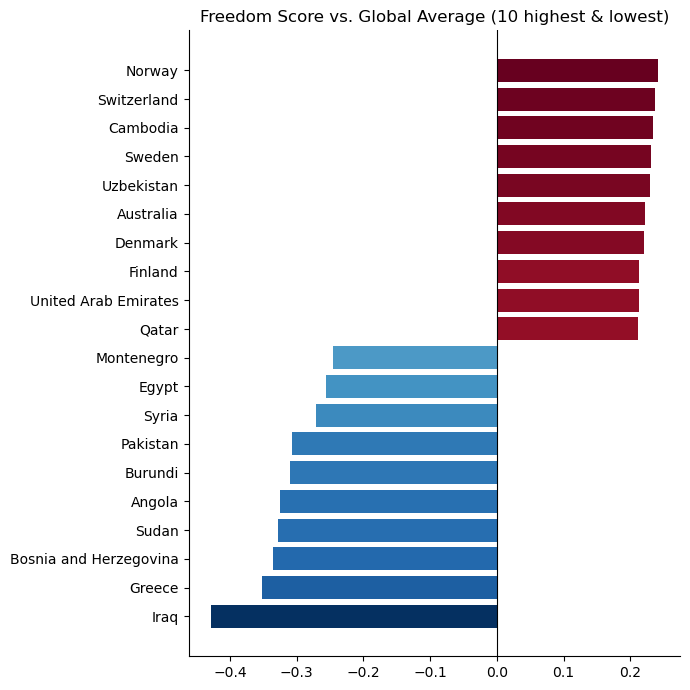

In [9]:
# Deviation from the global mean, not raw values
freedom_dev = df["Freedom"] - df["Freedom"].mean()

df_dev = df.assign(freedom_dev=freedom_dev)
sample = pd.concat([df_dev.nlargest(10, "freedom_dev"), df_dev.nsmallest(10, "freedom_dev")])
sample = sample.sort_values("freedom_dev")

# Centered at 0 so "above average" and "below average" are two color families meeting
# at a neutral midpoint, rather than the midpoint drifting wherever min/max happen to fall
norm = TwoSlopeNorm(vmin=sample["freedom_dev"].min(), vcenter=0, vmax=sample["freedom_dev"].max())

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(sample["Country"], sample["freedom_dev"], color=plt.cm.RdBu_r(norm(sample["freedom_dev"])))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Freedom Score vs. Global Average (10 highest & lowest)")
plt.tight_layout()
plt.show()

---
## Task 5 — Build an Accent Scale *(~6 min)*

Meera's note: *"Within Southern Asia, I want ONE chart that mutes every country to gray
EXCEPT the country with the highest Generosity score and the country with the lowest --
those two are the story. Use vivid, contrasting accent colors for just those two."*

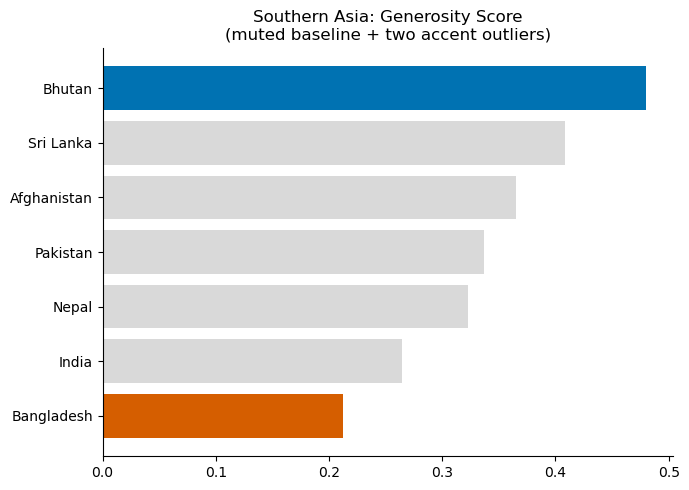

In [10]:
region_df = df[df["Region"] == "Southern Asia"].sort_values("Generosity")

lowest_country = region_df.iloc[0]["Country"]
highest_country = region_df.iloc[-1]["Country"]

colors = ["#d9d9d9"] * len(region_df)
colors[list(region_df["Country"]).index(lowest_country)] = "#D55E00"
colors[list(region_df["Country"]).index(highest_country)] = "#0072B2"

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(region_df["Country"], region_df["Generosity"], color=colors)
ax.set_title("Southern Asia: Generosity Score\n(muted baseline + two accent outliers)")
plt.tight_layout()
plt.show()

---
## Task 6 — Kill the Rainbow Colormap *(~5 min)*

Meera's note: *"Whoever built this heatmap used 'jet'. Convert it to grayscale first so
you can SEE why that's a problem, then replace it with a perceptually uniform
colormap."*

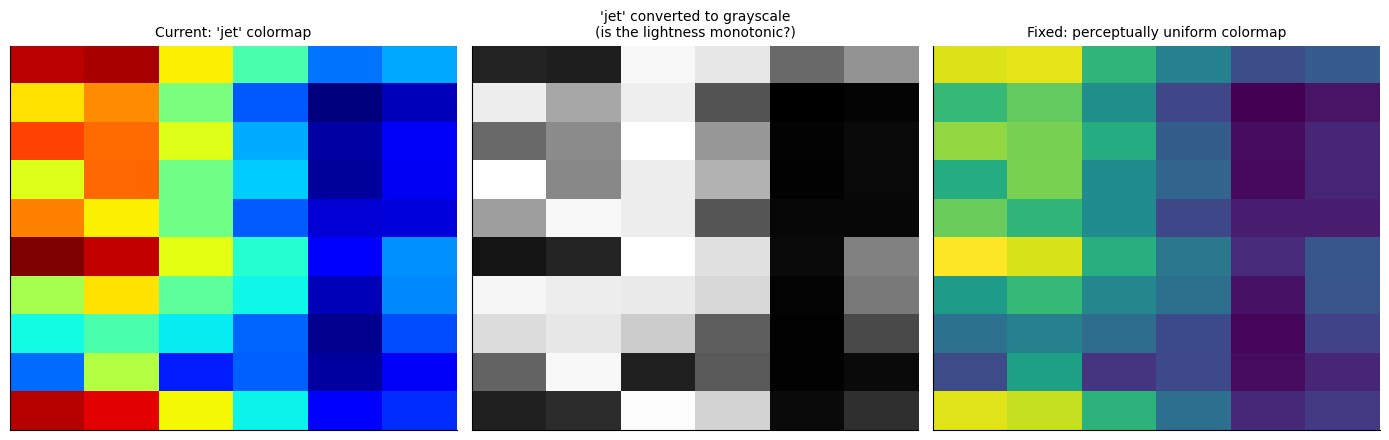

: 

In [ ]:
matrix = df.groupby("Region")[factor_cols].mean().values

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

axes[0].imshow(matrix, cmap="jet", aspect="auto")
axes[0].set_title("Current: 'jet' colormap", fontsize=10)

# Convert the 'jet'-mapped matrix to grayscale using luminance weights, to reveal
# that jet's lightness is NOT monotonic (it bounces bright-dark-bright-dark)
jet_rgba = plt.cm.jet(plt.Normalize()(matrix))
gray_jet = (jet_rgba[..., 0] * 0.2126 + jet_rgba[..., 1] * 0.7152 + jet_rgba[..., 2] * 0.0722)
axes[1].imshow(gray_jet, cmap="gray", aspect="auto")
axes[1].set_title("'jet' converted to grayscale\n(is the lightness monotonic?)", fontsize=10)

# Perceptually uniform colormap: lightness increases monotonically with value
axes[2].imshow(matrix, cmap="viridis", aspect="auto")
axes[2].set_title("Fixed: perceptually uniform colormap", fontsize=10)

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

---
## Reflection *(~5 min)*

Answer briefly in this markdown cell:

1. Which of the six fixes above would most change a policymaker's takeaway if left
   broken, and why?
2. Explain in your own words why the diverging scale (Task 4) needed a *centered*
   normalization instead of just min-to-max scaling.
3. Why is "it just needs to look distinct" not a sufficient bar for a qualitative color
   scale (Task 3)? What's the extra requirement from the lecture?
4. Complete the lecture's core idea in one sentence: a good color scale should
   *__________* the viewer, not *__________* them.

**Your answers:**

1. Task 6, involving the 'jet' rainbow colormap, would have the biggest impact on a policymaker's interpretation if it remained incorrect. The jet colormap can create visual boundaries that do not actually exist in the data because its brightness changes unevenly. As a result, small differences can appear much more significant than they really are, while meaningful differences may be difficult to notice. A policymaker could therefore incorrectly identify a region as performing much worse simply because of the way the colors are displayed.

2. Min-to-max normalization does not guarantee that zero is represented by the middle of the color scale. If the data range is uneven, zero may be positioned closer to one extreme, causing an average or zero-deviation value to appear more strongly colored. Using centered normalization with TwoSlopeNorm(vcenter=0) ensures that zero always receives the neutral color. This makes the visualization correctly distinguish values above and below the average.

3. Having colors that are simply different is not enough for a qualitative scale because the colors should also have similar visual importance. If one category has a much brighter or stronger color than the others, viewers may naturally assume that category is more important or extreme, even though the categories have no inherent ranking. The lecture's additional requirement is that qualitative colors should be perceptually balanced/equal-weighted, so that no category is unintentionally emphasized.

4. A good color scale should inform the viewer, not mislead them.